In [36]:
import datasets; print(datasets.__version__)

5.0.0


German & English from the same Dataset Experiment (twitter)



In [37]:
import pandas as pd
from huggingface_hub import list_repo_files

def load_hf(repo, config="", split="test"):
    prefix = f"{config}/{split}/" if config else f"{split}/"
    files = list_repo_files(repo, repo_type="dataset", revision="refs/convert/parquet")
    hits = sorted(f for f in files if f.startswith(prefix) and f.endswith(".parquet"))
    base = f"hf://datasets/{repo}@refs%2Fconvert%2Fparquet"
    return pd.concat([pd.read_parquet(f"{base}/{f}") for f in hits], ignore_index=True)

en = load_hf("cardiffnlp/tweet_sentiment_multilingual", "english")
de = load_hf("cardiffnlp/tweet_sentiment_multilingual", "german")
print(en.shape, de.shape, en.columns.tolist(), dict(en["label"].value_counts()))

(870, 2) (870, 2) ['text', 'label'] {0: np.int64(290), 1: np.int64(290), 2: np.int64(290)}


In [38]:
ja = load_hf("llm-book/wrime-sentiment", "default")
he = load_hf("omilab/hebrew_sentiment", "token")

for name, df in [("ja", ja), ("he", he)]:
    print(name, df.shape, df.columns.tolist())
    print(df.head(3).to_string(), "\n")

ja (1781, 4) ['sentence', 'label', 'user_id', 'datetime']
                                                                                sentence  label  user_id        datetime
0                                 鳥取砂丘の観光客が少なかったので、いつもならお昼前に渋滞するうちの前の道路がガラガラ。こんなことはまずない。      0        5  2020/5/6 12:17
1   ヒルナンデスで倉敷美観地区のロケ再放送してた。おしゃれなスポットになっているなあ。倉吉の白壁土蔵群もあんな感じで盛り上がったらなー。美観地区に似たような白い蔵があった。      0        5  2020/5/6 12:51
2  先週買い替えたスマホの人工知能がため口で「〜だぜ！〜よな！」と話しかけてくる。スマホの振動で勝手に起動して大声で長々しゃべるから、恥ずかしかった。まだ止めかたわからない。      1        5  2020/5/6 14:09 

he (2560, 2) ['text', 'label']
                                                                                                                                                                                                                                                                                                                                                                                                                  text  label
0   שמע ישר

In [39]:
TWEET = "cardiffnlp/tweet_sentiment_multilingual"

SOURCES = {
    "en": (TWEET, "english", "text", {0: "negative", 2: "positive"}),
    "de": (TWEET, "german", "text", {0: "negative", 2: "positive"}),
    "ja": ("llm-book/wrime-sentiment", "default", "sentence", {0: "positive", 1: "negative"}),
    "he": ("omilab/hebrew_sentiment", "token", "text", {0: "positive", 1: "negative"}),
}

def load_language(lang, n_per_class=290, seed=42): #290 is max 
    repo, config, text_col, label_map = SOURCES[lang]
    raw = load_hf(repo, config)
    df = pd.DataFrame({
        "text": raw[text_col].astype(str),
        "label": raw["label"].map(label_map),
    }).dropna()
    n = min(n_per_class, df["label"].value_counts().min())
    df = df.groupby("label").sample(n=n, random_state=seed)
    df["language"] = lang
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

data = pd.concat([load_language(l) for l in SOURCES], ignore_index=True)
print(data.groupby(["language", "label"]).size())

language  label   
de        negative    290
          positive    290
en        negative    290
          positive    290
he        negative    290
          positive    290
ja        negative    290
          positive    290
dtype: int64


In [40]:
# Use a pipeline as a high-level helper
#XML ROBERTA  
from transformers import pipeline

pipe = pipeline("zero-shot-classification", model="joeddav/xlm-roberta-large-xnli")



Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 
roberta.pooler.dense.bias       | UNEXPECTED |  | 
roberta.pooler.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [41]:
#test run
print(pipe("Sieht super aus", candidate_labels=["positive", "negative"]))
print(pipe("looks great", candidate_labels=["positive", "negative"]))
print(pipe("すごく素敵ですね", candidate_labels=["positive", "negative"]))
print(pipe("נראה מצוין", candidate_labels=["positive", "negative"]))

{'sequence': 'Sieht super aus', 'labels': ['positive', 'negative'], 'scores': [0.988085150718689, 0.011914880014955997]}
{'sequence': 'looks great', 'labels': ['positive', 'negative'], 'scores': [0.9850455522537231, 0.014954461716115475]}
{'sequence': 'すごく素敵ですね', 'labels': ['positive', 'negative'], 'scores': [0.9612066745758057, 0.038793254643678665]}
{'sequence': 'נראה מצוין', 'labels': ['positive', 'negative'], 'scores': [0.9895409941673279, 0.010458997450768948]}


In [42]:
# Load model directly
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tokenizer = AutoTokenizer.from_pretrained("joeddav/xlm-roberta-large-xnli")
model = AutoModelForSequenceClassification.from_pretrained("joeddav/xlm-roberta-large-xnli", device_map="auto")

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                             | Status     |  | 
--------------------------------+------------+--+-
roberta.embeddings.position_ids | UNEXPECTED |  | 
roberta.pooler.dense.bias       | UNEXPECTED |  | 
roberta.pooler.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [43]:
import pandas as pd, os

LABELS = {
    "en": ["positive", "negative"],
    "de": ["positiv", "negativ"],
    "ja": ["ポジティブ", "ネガティブ"],
    "he": ["חיובי", "שלילי"],
}
CANON = {"positive":"positive","negative":"negative","positiv":"positive","negativ":"negative",
         "ポジティブ":"positive","ネガティブ":"negative","חיובי":"positive","שלילי":"negative"}

TEMPLATES = {
    "default":      (False, "This example is {}."),
    "sentiment_en": (False, "The sentiment of this text is {}."),
    "native":       (True, {"en": "The sentiment of this text is {}.",
                            "de": "Die Stimmung dieses Textes ist {}.",
                            "ja": "このテキストの感情は{}です。",
                            "he": "הרגש בטקסט הזה הוא {}."}),
}

os.makedirs("/kaggle/working/results", exist_ok=True)
rows = []

for lang, g in data.groupby("language"):
    for key, (native, tmpl) in TEMPLATES.items():
        labels = LABELS[lang] if native else ["positive", "negative"]
        template = tmpl[lang] if native else tmpl
        res = pipe(g["text"].tolist(), candidate_labels=labels,
                   hypothesis_template=template, batch_size=32)
        out = g.copy()
        out["pred"] = [CANON[r["labels"][0]] for r in res]
        out["score"] = [r["scores"][0] for r in res]
        out["template"] = key
        rows.append(out)
        print(f"{lang} {key}: {(out['pred'] == out['label']).mean():.3f}")

preds = pd.concat(rows, ignore_index=True)
preds.to_csv("/kaggle/working/results/predictions.csv", index=False)
print("\ngespeichert:", preds.shape)

de default: 0.809
de sentiment_en: 0.833
de native: 0.848
en default: 0.862
en sentiment_en: 0.883
en native: 0.883
he default: 0.778
he sentiment_en: 0.767
he native: 0.781
ja default: 0.778
ja sentiment_en: 0.848
ja native: 0.840

gespeichert: (6960, 6)


In [44]:
import numpy as np, pandas as pd
from sklearn.metrics import f1_score, confusion_matrix, classification_report

preds = pd.read_csv("/kaggle/working/results/predictions.csv")

summary = (preds.groupby(["language", "template"])
    .apply(lambda g: pd.Series({
        "accuracy": (g["pred"] == g["label"]).mean(),
        "macro_f1": f1_score(g["label"], g["pred"], average="macro"),
        "n": len(g)}), include_groups=False)
    .reset_index())
summary["ci95"] = 1.96 * np.sqrt(summary["accuracy"] * (1 - summary["accuracy"]) / summary["n"])

print(summary.round(3).to_string(index=False))
summary.to_csv("/kaggle/working/results/summary.csv", index=False)

with open("/kaggle/working/results/summary.tex", "w") as f:
    f.write(summary.round(3).to_latex(index=False))

language     template  accuracy  macro_f1     n  ci95
      de      default     0.809     0.808 580.0 0.032
      de       native     0.848     0.848 580.0 0.029
      de sentiment_en     0.833     0.833 580.0 0.030
      en      default     0.862     0.861 580.0 0.028
      en       native     0.883     0.883 580.0 0.026
      en sentiment_en     0.883     0.883 580.0 0.026
      he      default     0.778     0.777 580.0 0.034
      he       native     0.781     0.781 580.0 0.034
      he sentiment_en     0.767     0.766 580.0 0.034
      ja      default     0.778     0.775 580.0 0.034
      ja       native     0.840     0.840 580.0 0.030
      ja sentiment_en     0.848     0.848 580.0 0.029


In [45]:
from statsmodels.stats.contingency_tables import mcnemar

errors = (preds[preds["pred"] != preds["label"]]
          .sort_values("score", ascending=False)
          .groupby("language").head(30))
errors.to_csv("/kaggle/working/results/errors.csv", index=False)

sig = []
for lang in sorted(preds["language"].unique()):
    for t1, t2 in [("default","sentiment_en"), ("sentiment_en","native")]:
        a = preds[(preds.language==lang)&(preds.template==t1)].reset_index(drop=True)
        b = preds[(preds.language==lang)&(preds.template==t2)].reset_index(drop=True)
        ca, cb = a["pred"]==a["label"], b["pred"]==b["label"]
        tb = [[int((ca&cb).sum()), int((ca&~cb).sum())],
              [int((~ca&cb).sum()), int((~ca&~cb).sum())]]
        sig.append({"language": lang, "comparison": f"{t1} vs {t2}",
                    "p_value": mcnemar(tb, exact=False, correction=True).pvalue})

sig = pd.DataFrame(sig)
sig.to_csv("/kaggle/working/results/significance.csv", index=False)
print(sig.round(4).to_string(index=False))

language              comparison  p_value
      de default vs sentiment_en   0.0933
      de  sentiment_en vs native   0.1763
      en default vs sentiment_en   0.1757
      en  sentiment_en vs native   0.0000
      he default vs sentiment_en   0.5186
      he  sentiment_en vs native   0.1859
      ja default vs sentiment_en   0.0000
      ja  sentiment_en vs native   0.5510


/usr/local/lib/python3.12/dist-packages/statsmodels/stats/contingency_tables.py:1348: RuntimeWarning: divide by zero encountered in scalar divide
  statistic = (np.abs(n1 - n2) - corr)**2 / (1. * (n1 + n2))


In [46]:
from sklearn.metrics import confusion_matrix
g = preds[(preds.language=="ja") & (preds.template=="default")]
print(confusion_matrix(g["label"], g["pred"], labels=["positive","negative"]))
print("__________")
from sklearn.metrics import confusion_matrix
g = preds[(preds.language=="he") & (preds.template=="default")]
print(confusion_matrix(g["label"], g["pred"], labels=["positive","negative"]))
print("__________")
from sklearn.metrics import confusion_matrix
g = preds[(preds.language=="de") & (preds.template=="default")]
print(confusion_matrix(g["label"], g["pred"], labels=["positive","negative"]))
print("__________")
from sklearn.metrics import confusion_matrix
g = preds[(preds.language=="en") & (preds.template=="default")]
print(confusion_matrix(g["label"], g["pred"], labels=["positive","negative"]))



[[256  34]
 [ 95 195]]
__________
[[243  47]
 [ 82 208]]
__________
[[253  37]
 [ 74 216]]
__________
[[270  20]
 [ 60 230]]


In [47]:
for lang in ["ja","he","de","en"]:
    g = preds[(preds.language==lang) & (preds.template=="sentiment_en")]
    cm = confusion_matrix(g["label"], g["pred"], labels=["positive","negative"])
    print(lang, cm[0,0]/290, cm[1,1]/290)

ja 0.8862068965517241 0.8103448275862069
he 0.8310344827586207 0.7034482758620689
de 0.8517241379310345 0.8137931034482758
en 0.8896551724137931 0.8758620689655172


In [ ]:
for lang in ["en","de","ja","he"]:
    g = preds[(preds.language==lang) & (preds.template=="sentiment_en")]
    cm = confusion_matrix(g["label"], g["pred"], labels=["positive","negative"])
    rp, rn = cm[0,0]/290, cm[1,1]/290
    print(f"{lang}  pos={rp:.3f}  neg={rn:.3f}  acc={(rp+rn)/2:.3f}  bias={rp-rn:+.3f}")

print("__________")


for lang in ["en","de","ja","he"]:
    g = preds[(preds.language==lang) & (preds.template=="default")]
    cm = confusion_matrix(g["label"], g["pred"], labels=["positive","negative"])
    rp, rn = cm[0,0]/290, cm[1,1]/290
    print(f"{lang}  pos={rp:.3f}  neg={rn:.3f}  acc={(rp+rn)/2:.3f}  bias={rp-rn:+.3f}")

print("__________")


for lang in ["en","de","ja","he"]:
    g = preds[(preds.language==lang) & (preds.template=="native")]
    cm = confusion_matrix(g["label"], g["pred"], labels=["positive","negative"])
    rp, rn = cm[0,0]/290, cm[1,1]/290
    print(f"{lang}  pos={rp:.3f}  neg={rn:.3f}  acc={(rp+rn)/2:.3f}  bias={rp-rn:+.3f}")



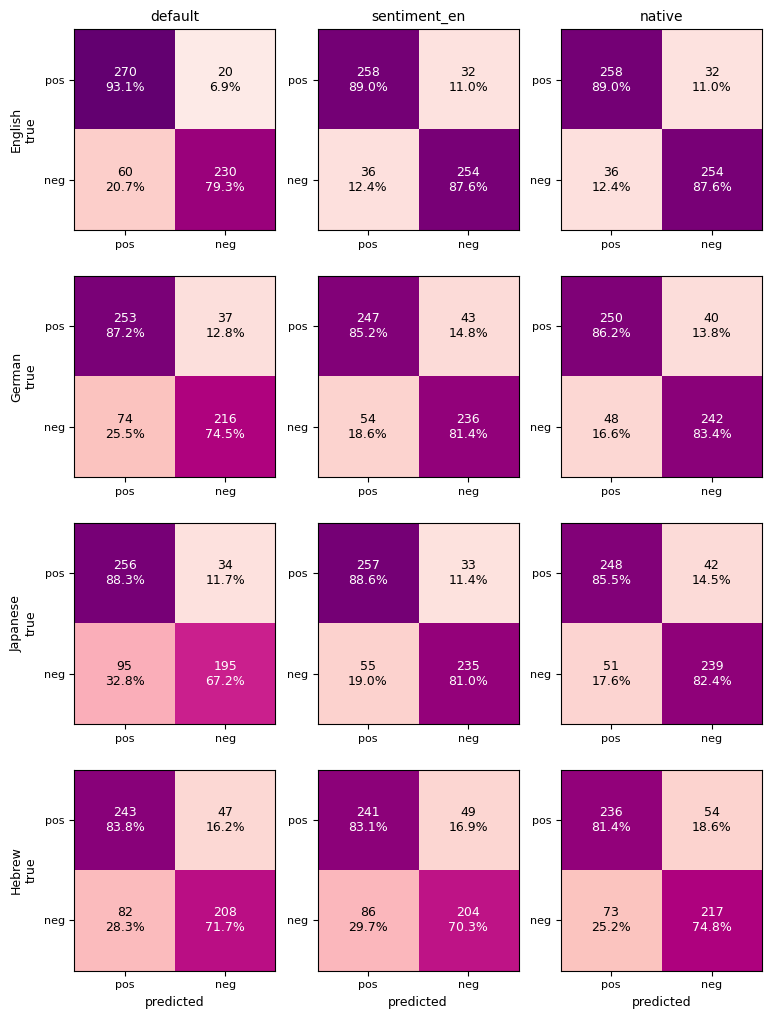

In [49]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

LABELS = ["positive", "negative"]
NAMES = {"en": "English", "de": "German", "ja": "Japanese", "he": "Hebrew"}
langs = ["en", "de", "ja", "he"]
templates = ["default", "sentiment_en", "native"]

fig, axes = plt.subplots(len(langs), len(templates),
                         figsize=(2.6 * len(templates), 2.6 * len(langs)))

for i, lang in enumerate(langs):
    for j, t in enumerate(templates):
        ax = axes[i, j]
        g = preds[(preds.language == lang) & (preds.template == t)]
        cm = confusion_matrix(g["label"], g["pred"], labels=LABELS)
        cmn = cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(cmn, cmap="RdPu", vmin=0, vmax=1)
        for a in range(2):
            for b in range(2):
                ax.text(b, a, f"{cm[a,b]}\n{cmn[a,b]:.1%}", ha="center", va="center",
                        fontsize=9, color="white" if cmn[a,b] > .5 else "black")
        ax.set_xticks([0,1], ["pos","neg"], fontsize=8)
        ax.set_yticks([0,1], ["pos","neg"], fontsize=8)
        if i == 0: ax.set_title(t, fontsize=10)
        if j == 0: ax.set_ylabel(NAMES[lang] + "\ntrue", fontsize=9)
        if i == len(langs)-1: ax.set_xlabel("predicted", fontsize=9)

fig.tight_layout()
fig.savefig("/kaggle/working/results/confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

german, english, japanese same


In [50]:
for lang in ["en", "de", "ja"]:
    df = load_hf(f"SetFit/amazon_reviews_multi_{lang}", "default")
    print(lang, df.shape, df.columns.tolist())
    print(df["label"].value_counts().sort_index())
    print(df.head(1).to_string(), "\n")

en (5000, 4) ['id', 'text', 'label', 'label_text']
label
0    1000
1    1000
2    1000
3    1000
4    1000
Name: count, dtype: int64
           id                                                                                                                                                                                                                                                                     text  label label_text
0  en_0199937  These are AWFUL. They are see through, the fabric feels like tablecloth, and they fit like children’s clothing. Customer service did seem to be nice though, but I regret missing my return date for these. I wouldn’t even donate them because the quality is so poor.      0          0 

de (5000, 4) ['id', 'text', 'label', 'label_text']
label
0    1000
1    1000
2    1000
3    1000
4    1000
Name: count, dtype: int64
           id                                                                                                                             

In [51]:
AMAZON = {
    "en": (f"SetFit/amazon_reviews_multi_en", "default"),
    "de": (f"SetFit/amazon_reviews_multi_de", "default"),
    "ja": (f"SetFit/amazon_reviews_multi_ja", "default"),
}
STARS = {0: "negative", 1: "negative", 3: "positive", 4: "positive"} 

def load_amazon(lang, n_per_class=290, seed=42):
    repo, config = AMAZON[lang]
    raw = load_hf(repo, config)
    df = pd.DataFrame({"text": raw["text"].astype(str),
                       "label": raw["label"].map(STARS)}).dropna()
    n = min(n_per_class, df["label"].value_counts().min())
    df = df.groupby("label").sample(n=n, random_state=seed)
    df["language"] = lang
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

data = pd.concat([load_amazon(l) for l in AMAZON], ignore_index=True)
print(data.groupby(["language", "label"]).size())

language  label   
de        negative    290
          positive    290
en        negative    290
          positive    290
ja        negative    290
          positive    290
dtype: int64


In [52]:
import os
os.makedirs("/kaggle/working/results", exist_ok=True)
rows = []


LABELS = {
    "en": ["positive", "negative"],
    "de": ["positiv", "negativ"],
    "ja": ["ポジティブ", "ネガティブ"],
    "he": ["חיובי", "שלילי"],
}

for lang, g in data.groupby("language"):
    for key, (native, tmpl) in TEMPLATES.items():
        labels = LABELS[lang] if native else ["positive", "negative"]
        template = tmpl[lang] if native else tmpl
        res = pipe(g["text"].tolist(), candidate_labels=labels,
                   hypothesis_template=template, batch_size=32)
        out = g.copy()
        out["pred"] = [CANON[r["labels"][0]] for r in res]
        out["score"] = [r["scores"][0] for r in res]
        out["template"] = key
        rows.append(out)
        print(f"{lang} {key}: {(out['pred'] == out['label']).mean():.3f}")

preds = pd.concat(rows, ignore_index=True)
preds.to_csv("/kaggle/working/results/predictions_amazon.csv", index=False)
print("\ngespeichert:", preds.shape)

de default: 0.859
de sentiment_en: 0.866
de native: 0.871
en default: 0.853
en sentiment_en: 0.857
en native: 0.857
ja default: 0.826
ja sentiment_en: 0.845
ja native: 0.829

gespeichert: (5220, 6)


In [54]:
import numpy as np, pandas as pd
from sklearn.metrics import f1_score

RUN, R = "amazon", "/kaggle/working/results"
preds = pd.read_csv(f"{R}/predictions_{RUN}.csv")

t = preds.groupby(["language", "template"]).apply(lambda g: pd.Series({
    "accuracy":   (g.pred == g.label).mean(),
    "macro_f1":   f1_score(g.label, g.pred, average="macro"),
    "recall_pos": (g[g.label == "positive"].pred == "positive").mean(),
    "recall_neg": (g[g.label == "negative"].pred == "negative").mean(),
    "n": len(g),
}), include_groups=False).reset_index()

t["bias"] = t.recall_pos - t.recall_neg
t["ci95"] = 1.96 * np.sqrt(t.accuracy * (1 - t.accuracy) / t.n)
t.to_csv(f"{R}/summary_{RUN}.csv", index=False)
print(t.round(3).to_string(index=False))

language     template  accuracy  macro_f1  recall_pos  recall_neg     n  bias  ci95
      de      default     0.859     0.858       0.934       0.783 580.0 0.152 0.028
      de       native     0.871     0.871       0.903       0.838 580.0 0.066 0.027
      de sentiment_en     0.866     0.865       0.903       0.828 580.0 0.076 0.028
      en      default     0.853     0.852       0.952       0.755 580.0 0.197 0.029
      en       native     0.857     0.856       0.924       0.790 580.0 0.134 0.028
      en sentiment_en     0.857     0.856       0.924       0.790 580.0 0.134 0.028
      ja      default     0.826     0.824       0.931       0.721 580.0 0.210 0.031
      ja       native     0.829     0.829       0.897       0.762 580.0 0.134 0.031
      ja sentiment_en     0.845     0.844       0.907       0.783 580.0 0.124 0.029


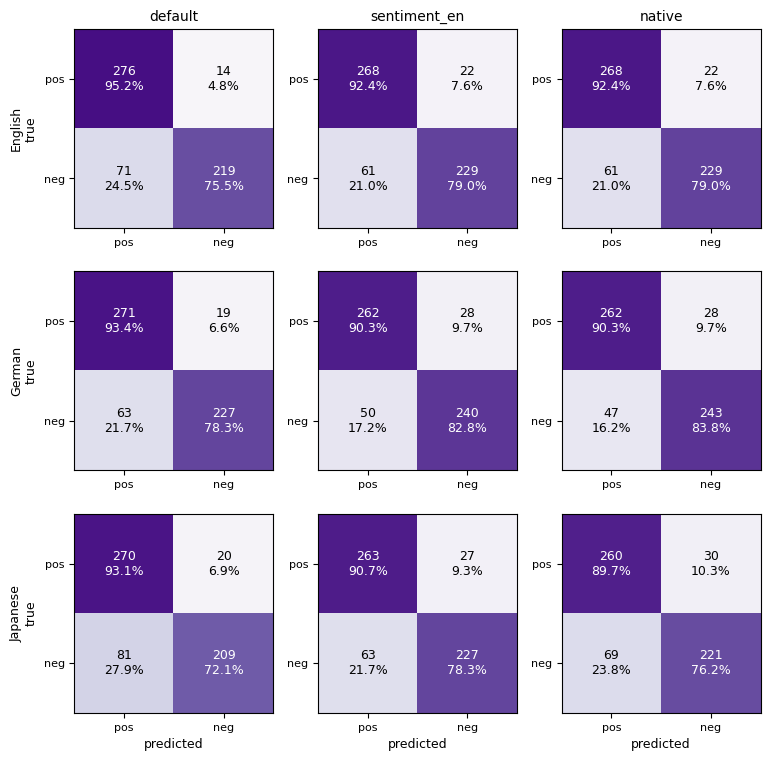

In [55]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

RUN, R = "amazon", "/kaggle/working/results"
preds = pd.read_csv(f"{R}/predictions_{RUN}.csv")

CLASSES = ["positive", "negative"]
NAMES = {"en": "English", "de": "German", "ja": "Japanese", "he": "Hebrew"}
langs = [l for l in ["en", "de", "ja", "he"] if l in set(preds.language)]
templates = ["default", "sentiment_en", "native"]

fig, axes = plt.subplots(len(langs), len(templates),
                         figsize=(2.6 * len(templates), 2.6 * len(langs)),
                         squeeze=False)

for i, lang in enumerate(langs):
    for j, tmpl in enumerate(templates):
        ax = axes[i, j]
        g = preds[(preds.language == lang) & (preds.template == tmpl)]
        cm = confusion_matrix(g["label"], g["pred"], labels=CLASSES)
        cmn = cm / cm.sum(axis=1, keepdims=True)
        ax.imshow(cmn, cmap="Purples", vmin=0, vmax=1)
        for a in range(2):
            for b in range(2):
                ax.text(b, a, f"{cm[a,b]}\n{cmn[a,b]:.1%}", ha="center", va="center",
                        fontsize=9, color="white" if cmn[a,b] > .5 else "black")
        ax.set_xticks([0,1], ["pos","neg"], fontsize=8)
        ax.set_yticks([0,1], ["pos","neg"], fontsize=8)
        if i == 0: ax.set_title(tmpl, fontsize=10)
        if j == 0: ax.set_ylabel(NAMES[lang] + "\ntrue", fontsize=9)
        if i == len(langs)-1: ax.set_xlabel("predicted", fontsize=9)

fig.tight_layout()
fig.savefig(f"{R}/confusion_matrices_{RUN}.png", dpi=200, bbox_inches="tight")
plt.show()

In [56]:
from datasets import load_dataset

ds = load_dataset("HebArabNlpProject/HebrewSentiment")

README.md:   0%|          | 0.00/560 [00:00<?, ?B/s]

HebSentiment_train.jsonl:   0%|          | 0.00/12.9M [00:00<?, ?B/s]

HebSentiment_val.jsonl: 0.00B [00:00, ?B/s]

test_test.jsonl: 0.00B [00:00, ?B/s]

HebSentiment_test.jsonl: 0.00B [00:00, ?B/s]

Generating train split:   0%|          | 0/35135 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6510 [00:00<?, ? examples/s]

In [57]:
he2 = load_hf("HebArabNlpProject/HebrewSentiment", "default")
print(he2.shape, he2.columns.tolist())
print(he2["tag_ids"].value_counts())

(6510, 9) ['id', 'task_name', 'tag_ids', 'text', 'campaign_id', 'annotator_agreement_strength', 'survey_name', 'industry', 'type']
tag_ids
Neutral     3699
Positive    1509
Negative    1299
Neutral        3
Name: count, dtype: int64


In [58]:
he2["tag_ids"] = he2["tag_ids"].str.strip()
print(he2["tag_ids"].value_counts())

tag_ids
Neutral     3702
Positive    1509
Negative    1299
Name: count, dtype: int64


In [59]:
MAP = {"Positive": "positive", "Negative": "negative"}

df = pd.DataFrame({
    "text": he2["text"].astype(str),
    "label": he2["tag_ids"].str.strip().map(MAP),
}).dropna()

print(df["label"].value_counts())

label
positive    1509
negative    1299
Name: count, dtype: int64


In [60]:
strong = he2[he2["annotator_agreement_strength"].str.strip() == "Strong"]
print(strong["tag_ids"].str.strip().value_counts())

tag_ids
Neutral     3525
Positive    1428
Negative    1224
Name: count, dtype: int64


In [61]:
MAP = {"Positive": "positive", "Negative": "negative"}

def load_he2(n_per_class=290, seed=42, strong_only=True):
    raw = load_hf("HebArabNlpProject/HebrewSentiment", "default")
    if strong_only:
        raw = raw[raw["annotator_agreement_strength"].str.strip() == "Strong"]
    df = pd.DataFrame({
        "text": raw["text"].astype(str),
        "label": raw["tag_ids"].str.strip().map(MAP),
    }).dropna()
    n = min(n_per_class, df["label"].value_counts().min())
    df = df.groupby("label").sample(n=n, random_state=seed)
    df["language"] = "he"
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)

he_data = load_he2()
print(he_data["label"].value_counts())

label
positive    290
negative    290
Name: count, dtype: int64


In [62]:
data = pd.concat([data, he_data], ignore_index=True)
print(data.groupby(["language", "label"]).size())

language  label   
de        negative    290
          positive    290
en        negative    290
          positive    290
he        negative    290
          positive    290
ja        negative    290
          positive    290
dtype: int64


In [63]:
print(type(LABELS))

<class 'dict'>


In [64]:
rows = []
for lang, g in data.groupby("language"):
    for key, (native, tmpl) in TEMPLATES.items():
        labels = LABELS[lang] if native else ["positive", "negative"]
        template = tmpl[lang] if native else tmpl
        res = pipe(g["text"].tolist(), candidate_labels=labels,
                   hypothesis_template=template, batch_size=32)
        out = g.copy()
        out["pred"] = [CANON[r["labels"][0]] for r in res]
        out["score"] = [r["scores"][0] for r in res]
        out["template"] = key
        rows.append(out)
        print(f"{lang} {key}: {(out['pred'] == out['label']).mean():.3f}")

preds = pd.concat(rows, ignore_index=True)
preds.to_csv("/kaggle/working/results/predictions_amazon_he.csv", index=False)
print("\ngespeichert:", preds.shape)

de default: 0.859
de sentiment_en: 0.866
de native: 0.871
en default: 0.853
en sentiment_en: 0.857
en native: 0.857
he default: 0.881
he sentiment_en: 0.903
he native: 0.914
ja default: 0.826
ja sentiment_en: 0.845
ja native: 0.829

gespeichert: (6960, 6)


In [65]:
print(data.groupby("language")["text"].apply(lambda s: s.str.len().median()))

language
de    147.0
en    124.0
he     37.0
ja     70.0
Name: text, dtype: float64


In [67]:
p = pd.read_csv("/kaggle/working/results/predictions_amazon_he.csv")
p["len"] = p["text"].str.len()
p["bin"] = pd.cut(p["len"], [0, 50, 100, 200, 10000],
                  labels=["<50", "50-100", "100-200", ">200"])
print(p[p.template == "sentiment_en"]
      .groupby(["language", "bin"], observed=True)
      .apply(lambda g: pd.Series({"acc": (g.pred == g.label).mean(), "n": len(g)}),
             include_groups=False).round(3))

                    acc      n
language bin                  
de       <50      0.920   75.0
         50-100   0.827  110.0
         100-200  0.879  198.0
         >200     0.853  197.0
en       <50      0.901  111.0
         50-100   0.856  139.0
         100-200  0.832  149.0
         >200     0.851  181.0
he       <50      0.918  390.0
         50-100   0.874  159.0
         100-200  0.867   30.0
         >200     1.000    1.0
ja       <50      0.853  197.0
         50-100   0.831  183.0
         100-200  0.854  137.0
         >200     0.841   63.0


In [68]:
p[p.template == "sentiment_en"].groupby(["language", "bin"], observed=True).apply(
    lambda g: pd.Series({"acc": (g.pred == g.label).mean(), "n": len(g)}),
    include_groups=False).round(3).to_csv("/kaggle/working/results/length_control.csv")

In [69]:
import numpy as np, pandas as pd
from sklearn.metrics import f1_score

for run in ["", "_amazon", "_amazon_he"]:
    p = pd.read_csv(f"/kaggle/working/results/predictions{run}.csv")
    t = p.groupby(["language","template"]).apply(lambda g: pd.Series({
        "accuracy": (g.pred==g.label).mean(),
        "recall_pos": (g[g.label=="positive"].pred=="positive").mean(),
        "recall_neg": (g[g.label=="negative"].pred=="negative").mean(),
        "n": len(g)}), include_groups=False).reset_index()
    t["bias"] = t.recall_pos - t.recall_neg
    t["ci95"] = 1.96*np.sqrt(t.accuracy*(1-t.accuracy)/t.n)
    print(f"=== {run or 'social'} ===")
    print(t.round(3).to_string(index=False), "\n")

=== social ===
language     template  accuracy  recall_pos  recall_neg     n  bias  ci95
      de      default     0.809       0.872       0.745 580.0 0.128 0.032
      de       native     0.848       0.862       0.834 580.0 0.028 0.029
      de sentiment_en     0.833       0.852       0.814 580.0 0.038 0.030
      en      default     0.862       0.931       0.793 580.0 0.138 0.028
      en       native     0.883       0.890       0.876 580.0 0.014 0.026
      en sentiment_en     0.883       0.890       0.876 580.0 0.014 0.026
      he      default     0.778       0.838       0.717 580.0 0.121 0.034
      he       native     0.781       0.814       0.748 580.0 0.066 0.034
      he sentiment_en     0.767       0.831       0.703 580.0 0.128 0.034
      ja      default     0.778       0.883       0.672 580.0 0.210 0.034
      ja       native     0.840       0.855       0.824 580.0 0.031 0.030
      ja sentiment_en     0.848       0.886       0.810 580.0 0.076 0.029 

=== _amazon ===
langu

In [70]:
print(p.drop_duplicates("text").groupby("language")["text"].apply(
    lambda s: s.str.len().describe().round(0)))

language       
de        count     580.0
          mean      203.0
          std       228.0
          min        20.0
          25%        83.0
          50%       147.0
          75%       245.0
          max      3775.0
en        count     580.0
          mean      170.0
          std       152.0
          min        20.0
          25%        61.0
          50%       124.0
          75%       226.0
          max       995.0
he        count     473.0
          mean       44.0
          std        29.0
          min         8.0
          25%        24.0
          50%        37.0
          75%        56.0
          max       223.0
ja        count     580.0
          mean      103.0
          std       105.0
          min        15.0
          25%        43.0
          50%        70.0
          75%       127.0
          max      1030.0
Name: text, dtype: float64


In [71]:
for run in ["", "_amazon_he"]:
    p = pd.read_csv(f"/kaggle/working/results/predictions{run}.csv")
    d = p[p.template == "default"]
    print(run or "social")
    print(d.groupby("language")["text"].agg(["size", "nunique"]), "\n")

social
          size  nunique
language               
de         580      580
en         580      580
he         580      564
ja         580      580 

_amazon_he
          size  nunique
language               
de         580      580
en         580      580
he         580      473
ja         580      580 



In [72]:
for run in ["", "_amazon_he"]:
    p = pd.read_csv(f"/kaggle/working/results/predictions{run}.csv")
    d = p[p.template == "default"]
    print(run or "social")
    print(d.groupby("language")["text"].apply(lambda s: s.str.len().median()), "\n")

social
language
de    66.0
en    99.0
he    67.0
ja    41.0
Name: text, dtype: float64 

_amazon_he
language
de    147.0
en    124.0
he     37.0
ja     70.0
Name: text, dtype: float64 



In [73]:
import numpy as np, pandas as pd
from sklearn.metrics import f1_score

for run in ["", "_amazon", "_amazon_he"]:
    p = pd.read_csv(f"/kaggle/working/results/predictions{run}.csv")
    t = p.groupby(["language","template"]).apply(lambda g: pd.Series({
        "accuracy": (g.pred==g.label).mean(),
        "recall_pos": (g[g.label=="positive"].pred=="positive").mean(),
        "recall_neg": (g[g.label=="negative"].pred=="negative").mean(),
        "n": len(g)}), include_groups=False).reset_index()
    t["bias"] = t.recall_pos - t.recall_neg
    t["ci95"] = 1.96*np.sqrt(t.accuracy*(1-t.accuracy)/t.n)
    print(f"=== {run or 'social'} ===")
    print(t.round(3).to_string(index=False), "\n")

=== social ===
language     template  accuracy  recall_pos  recall_neg     n  bias  ci95
      de      default     0.809       0.872       0.745 580.0 0.128 0.032
      de       native     0.848       0.862       0.834 580.0 0.028 0.029
      de sentiment_en     0.833       0.852       0.814 580.0 0.038 0.030
      en      default     0.862       0.931       0.793 580.0 0.138 0.028
      en       native     0.883       0.890       0.876 580.0 0.014 0.026
      en sentiment_en     0.883       0.890       0.876 580.0 0.014 0.026
      he      default     0.778       0.838       0.717 580.0 0.121 0.034
      he       native     0.781       0.814       0.748 580.0 0.066 0.034
      he sentiment_en     0.767       0.831       0.703 580.0 0.128 0.034
      ja      default     0.778       0.883       0.672 580.0 0.210 0.034
      ja       native     0.840       0.855       0.824 580.0 0.031 0.030
      ja sentiment_en     0.848       0.886       0.810 580.0 0.076 0.029 

=== _amazon ===
langu

In [74]:
t.ci95.min() 
t.ci95.max()

0.03086331167493833

In [75]:
import pandas as pd
from statsmodels.stats.contingency_tables import mcnemar

for run in ["", "_amazon_he"]:
    p = pd.read_csv(f"/kaggle/working/results/predictions{run}.csv")
    print(f"=== {run or 'social'} ===")
    for lang in ["en", "de", "ja", "he"]:
        if lang not in set(p.language):
            continue
        for t1, t2 in [("default", "sentiment_en"), ("sentiment_en", "native")]:
            a = p[(p.language == lang) & (p.template == t1)].reset_index(drop=True)
            b = p[(p.language == lang) & (p.template == t2)].reset_index(drop=True)
            ca, cb = a.pred == a.label, b.pred == b.label
            n1, n2 = int((ca & ~cb).sum()), int((~ca & cb).sum())
            pv = float("nan") if n1 + n2 == 0 else mcnemar(
                [[int((ca & cb).sum()), n1], [n2, int((~ca & ~cb).sum())]],
                exact=False, correction=True).pvalue
            print(f"{lang:3} {t1:13} vs {t2:13} disc={n1+n2:3}  p={pv:.4f}")
    print()

=== social ===
en  default       vs sentiment_en  disc= 66  p=0.1757
en  sentiment_en  vs native        disc=  0  p=nan
de  default       vs sentiment_en  disc= 60  p=0.0933
de  sentiment_en  vs native        disc= 35  p=0.1763
ja  default       vs sentiment_en  disc= 83  p=0.0000
ja  sentiment_en  vs native        disc= 45  p=0.5510
he  default       vs sentiment_en  disc= 60  p=0.5186
he  sentiment_en  vs native        disc= 28  p=0.1859

=== _amazon_he ===
en  default       vs sentiment_en  disc= 56  p=0.8937
en  sentiment_en  vs native        disc=  0  p=nan
de  default       vs sentiment_en  disc= 50  p=0.6714
de  sentiment_en  vs native        disc= 25  p=0.6892
ja  default       vs sentiment_en  disc= 61  p=0.2004
ja  sentiment_en  vs native        disc= 39  p=0.2002
he  default       vs sentiment_en  disc= 43  p=0.0673
he  sentiment_en  vs native        disc= 24  p=0.3074



In [76]:
print(f"p={pv:.3e}")

p=3.074e-01


In [77]:
for run in ["", "_amazon_he"]:
    p = pd.read_csv(f"/kaggle/working/results/predictions{run}.csv")
    print(f"=== {run or 'social'} ===")
    for lang in ["en", "de", "ja", "he"]:
        if lang not in set(p.language): continue
        for t1, t2 in [("default","sentiment_en"), ("sentiment_en","native")]:
            a = p[(p.language==lang)&(p.template==t1)].reset_index(drop=True)
            b = p[(p.language==lang)&(p.template==t2)].reset_index(drop=True)
            ca, cb = a.pred==a.label, b.pred==b.label
            n1, n2 = int((ca&~cb).sum()), int((~ca&cb).sum())
            pv = float("nan") if n1+n2==0 else mcnemar(
                [[int((ca&cb).sum()), n1],[n2, int((~ca&~cb).sum())]],
                exact=False, correction=True).pvalue
            print(f"{lang:3} {t1:13} vs {t2:13} disc={n1+n2:3}  p={pv:.3e}")
    print()




=== social ===
en  default       vs sentiment_en  disc= 66  p=1.757e-01
en  sentiment_en  vs native        disc=  0  p=nan
de  default       vs sentiment_en  disc= 60  p=9.329e-02
de  sentiment_en  vs native        disc= 35  p=1.763e-01
ja  default       vs sentiment_en  disc= 83  p=1.131e-05
ja  sentiment_en  vs native        disc= 45  p=5.510e-01
he  default       vs sentiment_en  disc= 60  p=5.186e-01
he  sentiment_en  vs native        disc= 28  p=1.859e-01

=== _amazon_he ===
en  default       vs sentiment_en  disc= 56  p=8.937e-01
en  sentiment_en  vs native        disc=  0  p=nan
de  default       vs sentiment_en  disc= 50  p=6.714e-01
de  sentiment_en  vs native        disc= 25  p=6.892e-01
ja  default       vs sentiment_en  disc= 61  p=2.004e-01
ja  sentiment_en  vs native        disc= 39  p=2.002e-01
he  default       vs sentiment_en  disc= 43  p=6.725e-02
he  sentiment_en  vs native        disc= 24  p=3.074e-01



In [78]:
import pandas as pd
from statsmodels.stats.contingency_tables import mcnemar

for run in ["", "_amazon_he"]:
    p = pd.read_csv(f"/kaggle/working/results/predictions{run}.csv")
    print(f"=== {run or 'social'} ===")
    for lang in ["en", "de", "ja", "he"]:
        if lang not in set(p.language):
            continue
        for t1, t2 in [("default", "sentiment_en"), ("sentiment_en", "native"),("default","native")]:
            a = p[(p.language == lang) & (p.template == t1)].reset_index(drop=True)
            b = p[(p.language == lang) & (p.template == t2)].reset_index(drop=True)
            ca, cb = a.pred == a.label, b.pred == b.label
            n1, n2 = int((ca & ~cb).sum()), int((~ca & cb).sum())
            pv = float("nan") if n1 + n2 == 0 else mcnemar(
                [[int((ca & cb).sum()), n1], [n2, int((~ca & ~cb).sum())]],
                exact=False, correction=True).pvalue
            print(f"{lang:3} {t1:13} vs {t2:13} disc={n1+n2:3}  p={pv:.4f}")
    print()

=== social ===
en  default       vs sentiment_en  disc= 66  p=0.1757
en  sentiment_en  vs native        disc=  0  p=nan
en  default       vs native        disc= 66  p=0.1757
de  default       vs sentiment_en  disc= 60  p=0.0933
de  sentiment_en  vs native        disc= 35  p=0.1763
de  default       vs native        disc= 71  p=0.0090
ja  default       vs sentiment_en  disc= 83  p=0.0000
ja  sentiment_en  vs native        disc= 45  p=0.5510
ja  default       vs native        disc= 94  p=0.0003
he  default       vs sentiment_en  disc= 60  p=0.5186
he  sentiment_en  vs native        disc= 28  p=0.1859
he  default       vs native        disc= 62  p=0.8989

=== _amazon_he ===
en  default       vs sentiment_en  disc= 56  p=0.8937
en  sentiment_en  vs native        disc=  0  p=nan
en  default       vs native        disc= 56  p=0.8937
de  default       vs sentiment_en  disc= 50  p=0.6714
de  sentiment_en  vs native        disc= 25  p=0.6892
de  default       vs native        disc= 55  p=0.4185

In [81]:
p = pd.read_csv("/kaggle/working/results/predictions.csv")
a = p[(p.language=="de")&(p.template=="default")].reset_index(drop=True)
b = p[(p.language=="de")&(p.template=="native")].reset_index(drop=True)
ca, cb = a.pred==a.label, b.pred==b.label

print("both right:", (ca&cb).sum())
print("default:  ", (ca&~cb).sum())
print("native:   ", (~ca&cb).sum())
print("both wrong: ", (~ca&~cb).sum())
print("total:", (ca&cb).sum()+(ca&~cb).sum()+(~ca&cb).sum()+(~ca&~cb).sum())
print("acc default:", ca.mean(), "acc native:", cb.mean())
print((a.text == b.text).all())

both right: 445
default:   24
native:    47
both wrong:  64
total: 580
acc default: 0.8086206896551724 acc native: 0.8482758620689655
True


In [80]:
print(f"{lang:3} {t1:13} vs {t2:13} disc={n1+n2:3}  p={pv:.4f}")

he  default       vs native        disc= 57  p=0.0171
